# Import Libraries 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine
from dotenv import load_dotenv
import os

print("Libraries imported successfully!")

Libraries imported successfully!


# Connect python to neon postgreSQL

In [3]:
%pip install psycopg2-binary

   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   --------------- ------------------------ 1.0/2.8 MB 5.9 MB/s eta 0:00:01
   ------------------------------------- -- 2.6/2.8 MB 7.5 MB/s eta 0:00:01
   ------------------------------------- -- 2.6/2.8 MB 7.5 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 3.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [4]:
load_dotenv()

DATABASE_URL = os.getenv("DATABASE_URL")

if not DATABASE_URL:
    raise ValueError("DATABASE_URL not found in .env file")

DATABASE_URL = DATABASE_URL.replace(
    "postgresql://",
    "postgresql+psycopg2://",
    1
)

engine = create_engine(DATABASE_URL)

with engine.connect() as connection:
    result = connection.exec_driver_sql(
        "SELECT version();"
    )
    print("Connected successfully!")
    print(result.fetchone()[0])

Connected successfully!
PostgreSQL 18.7 (84da7d8) on aarch64-unknown-linux-gnu, compiled by gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0, 64-bit


# Extract all 8 SQL analytics tables

In [5]:
tables = [
    "monthly_sales",
    "customer_analytics",
    "customer_retention",
    "product_performance",
    "category_performance",
    "seller_performance",
    "payment_analytics",
    "delivery_review_analytics"
]

dataframes = {}

for table in tables:
    query = f"SELECT * FROM analytics.{table}"
    dataframes[table] = pd.read_sql(query, engine)
    print(f"{table}: {dataframes[table].shape}")

print("\nAll 8 analytics tables loaded successfully!")

monthly_sales: (22, 5)
customer_analytics: (93357, 5)
customer_retention: (218, 4)
product_performance: (32216, 5)
category_performance: (74, 5)
seller_performance: (2970, 5)
payment_analytics: (4, 7)
delivery_review_analytics: (23, 7)

All 8 analytics tables loaded successfully!


# Validate the extracted data

In [6]:
for name, df in dataframes.items():
    print(f"\n--- {name} ---")
    print("Rows:", len(df))
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())


--- monthly_sales ---
Rows: 22
Missing values: 0
Duplicate rows: 0

--- customer_analytics ---
Rows: 93357
Missing values: 0
Duplicate rows: 0

--- customer_retention ---
Rows: 218
Missing values: 0
Duplicate rows: 0

--- product_performance ---
Rows: 32216
Missing values: 0
Duplicate rows: 0

--- category_performance ---
Rows: 74
Missing values: 0
Duplicate rows: 0

--- seller_performance ---
Rows: 2970
Missing values: 0
Duplicate rows: 0

--- payment_analytics ---
Rows: 4
Missing values: 0
Duplicate rows: 0

--- delivery_review_analytics ---
Rows: 23
Missing values: 0
Duplicate rows: 0


# Sales performance analysis

In [7]:
sales = dataframes["monthly_sales"].copy()

sales["sales_month"] = pd.to_datetime(sales["sales_month"])
sales = sales.sort_values("sales_month")

total_revenue = sales["total_revenue"].sum()
total_orders = sales["total_orders"].sum()
overall_aov = total_revenue / total_orders

best_month = sales.loc[sales["total_revenue"].idxmax()]

sales["revenue_growth_pct"] = (
    sales["total_revenue"].pct_change() * 100
)

print(f"Total Revenue: R$ {total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Overall AOV: R$ {overall_aov:,.2f}")

print("\nBest Revenue Month:")
print(best_month[["sales_month", "total_revenue"]])

print("\nMonthly Revenue Growth:")
display(sales[["sales_month", "total_revenue", "revenue_growth_pct"]])

Total Revenue: R$ 15,422,461.77
Total Orders: 96,477
Overall AOV: R$ 159.86

Best Revenue Month:
sales_month      2017-11-01 00:00:00
total_revenue             1153528.05
Name: 12, dtype: object

Monthly Revenue Growth:


,sales_month,total_revenue,revenue_growth_pct
0,2016-10-01,46566.71,NaN
1,2016-12-01,19.62,-99.957867
2,2017-01-01,127545.67,649979.867482
3,2017-02-01,271298.65,112.707064
4,2017-03-01,414369.39,52.735515
5,2017-04-01,390952.18,-5.651289
6,2017-05-01,567066.73,45.047594
7,2017-06-01,490225.60,-13.550633
8,2017-07-01,566403.93,15.539443
9,2017-08-01,646000.61,14.052989


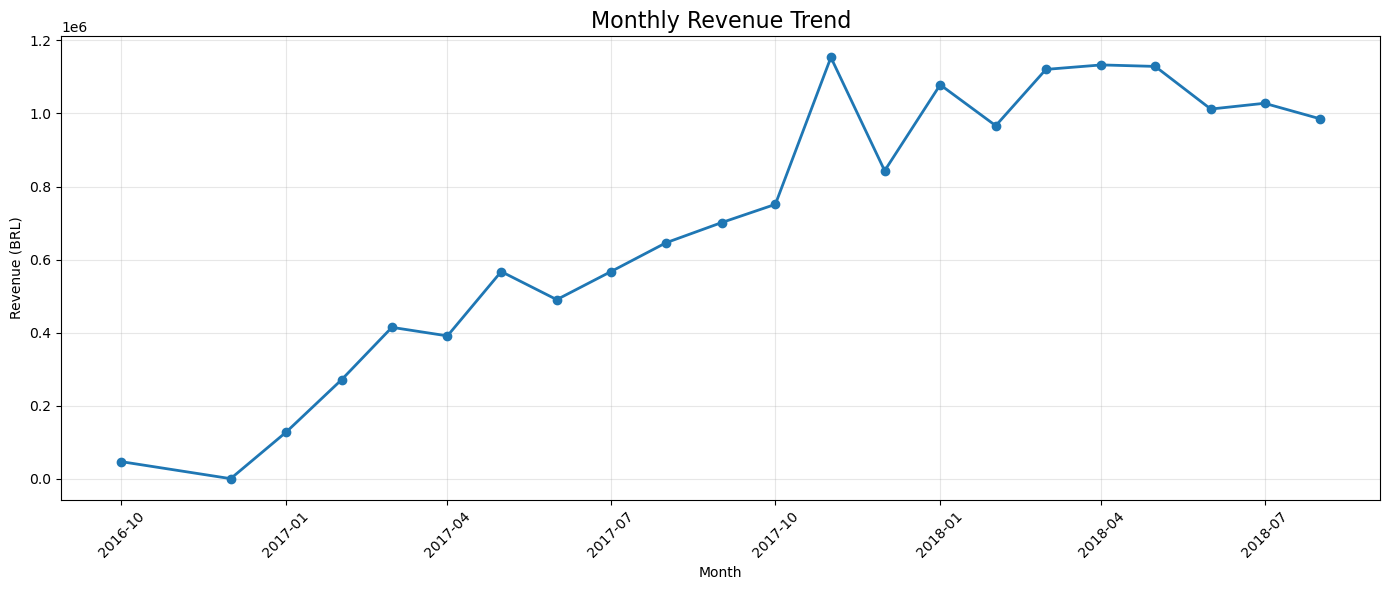

In [8]:
plt.figure(figsize=(14, 6))

plt.plot(
    sales["sales_month"],
    sales["total_revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()

- Identify revenue patterns, growth periods and fluctuations visually.

# Customer Analytics

In [9]:
customers = dataframes["customer_analytics"].copy()

# Count customers by order frequency
order_frequency = customers["total_orders"].value_counts().sort_index()

one_time_customers = (customers["total_orders"] == 1).sum()
repeat_customers = (customers["total_orders"] > 1).sum()

total_customers = len(customers)

print("Total Customers:", total_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)

print("\nCustomer Percentage:")
print("One-Time:", round(one_time_customers / total_customers * 100, 2), "%")
print("Repeat:", round(repeat_customers / total_customers * 100, 2), "%")

Total Customers: 93357
One-Time Customers: 90556
Repeat Customers: 2801

Customer Percentage:
One-Time: 97.0 %
Repeat: 3.0 %


# Customer Lifetime Value (CLV)

In [11]:
print(customers.columns.tolist())

['customer_unique_id', 'total_orders', 'first_purchase_date', 'last_purchase_date', 'lifetime_value']


In [12]:
clv = customers["lifetime_value"]

print("Average Customer Lifetime Value:",
      round(clv.mean(), 2))

print("Median Customer Lifetime Value:",
      round(clv.median(), 2))

print("Highest Customer Lifetime Value:",
      round(clv.max(), 2))

print("\nCLV Distribution:")
print(clv.describe())

Average Customer Lifetime Value: 165.2
Median Customer Lifetime Value: 107.78
Highest Customer Lifetime Value: 13664.08

CLV Distribution:
count    93357.000000
mean       165.198772
std        226.314579
min          9.590000
25%         63.060000
50%        107.780000
75%        182.560000
max      13664.080000
Name: lifetime_value, dtype: float64


# Visualise CLV distribution

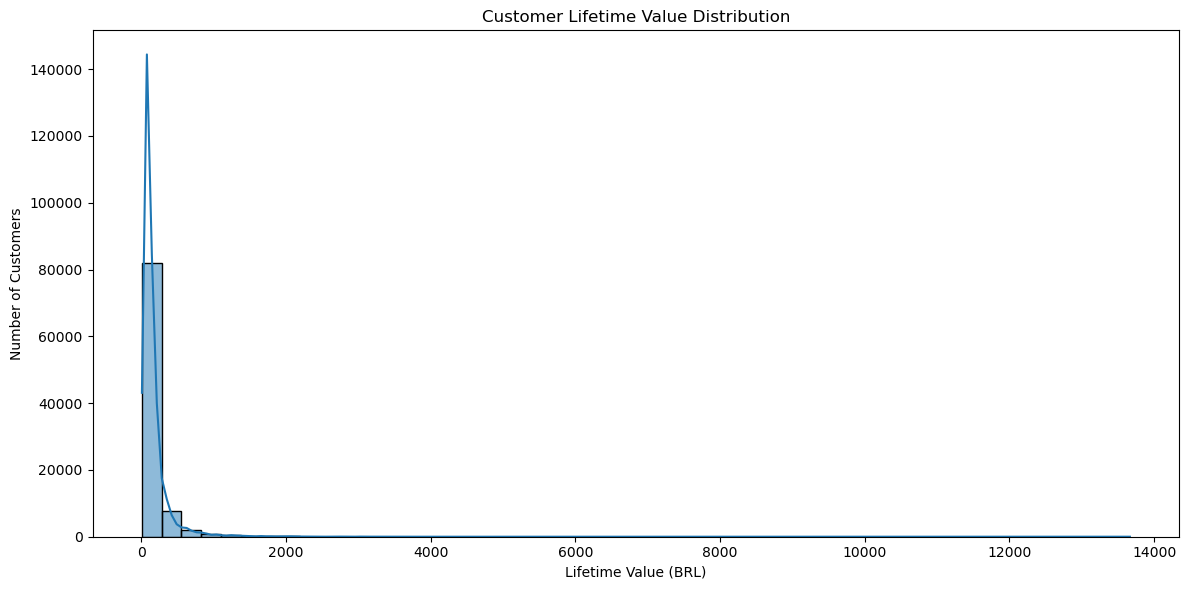

In [13]:
plt.figure(figsize=(12, 6))

sns.histplot(
    customers["lifetime_value"],
    bins=50,
    kde=True
)

plt.title("Customer Lifetime Value Distribution")
plt.xlabel("Lifetime Value (BRL)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

# Identify top 10 customers by lifetime value

In [14]:
top_customers = customers.nlargest(
    10, "lifetime_value"
)

display(
    top_customers[
        ["customer_unique_id", "total_orders", "lifetime_value"]
    ]
)

,customer_unique_id,total_orders,lifetime_value
3724,0a0a92112bd4c708ca5fde585afaa872,1,13664.08
79635,da122df9eeddfedc1dc1f5349a1a690c,2,7571.63
43168,763c8b1c9c68a0229c42c9fc6f662b93,1,7274.88
80462,dc4802a71eae9be1dd28f5d788ceb526,1,6929.31
25436,459bef486812aa25204be022145caa62,1,6922.21
93080,ff4159b92c40ebe40454e3e6a7c35ed6,1,6726.66
23411,4007669dec559734d6f53e029e360987,1,6081.54
87147,eebb5dda148d3893cdaf5b5ca3040ccb,1,4764.34
26640,48e1ac109decbb87765a3eade6854098,1,4681.78
73126,c8460e4251689ba205045f3ea17884a1,4,4655.91


# Visualise the top 10 customers

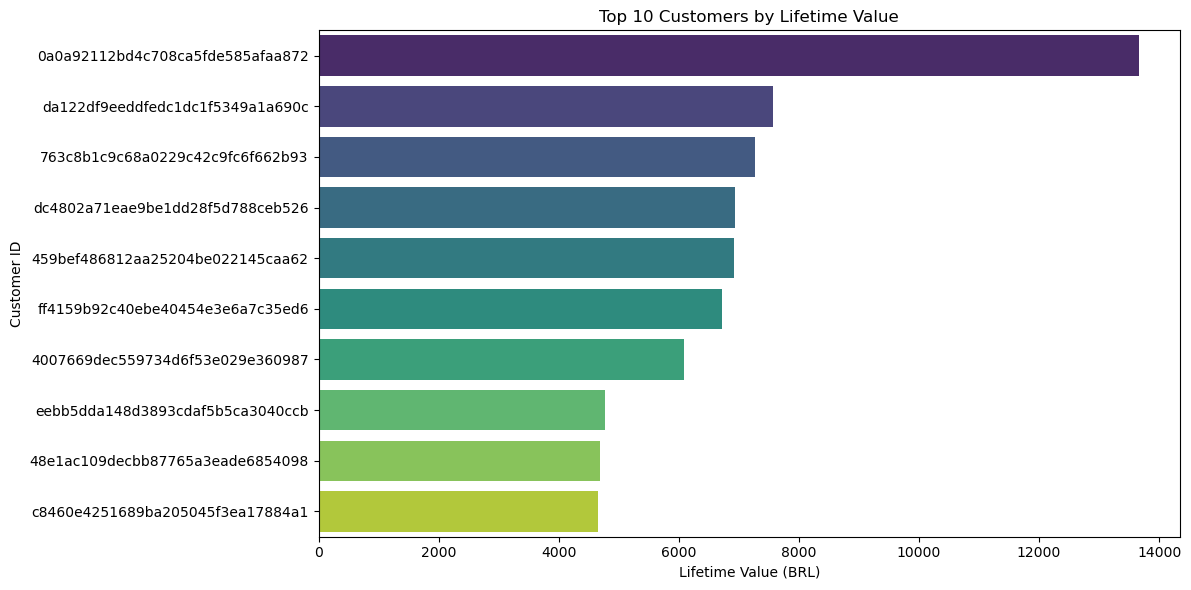

In [15]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_customers,
    x="lifetime_value",
    y="customer_unique_id",
    hue="customer_unique_id",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Customers by Lifetime Value")
plt.xlabel("Lifetime Value (BRL)")
plt.ylabel("Customer ID")

plt.tight_layout()

# Customer Retention & Cohort Analysis

In [16]:
retention = dataframes["customer_retention"].copy()

print("Columns:")
print(retention.columns.tolist())

print("\nSample records:")
display(retention.head(10))

Columns:
['cohort_month', 'activity_month', 'month_number', 'active_customers']

Sample records:


,cohort_month,activity_month,month_number,active_customers
0,2016-10-01,2016-10-01,0,262
1,2016-10-01,2017-04-01,6,1
2,2016-10-01,2017-07-01,9,1
3,2016-10-01,2017-09-01,11,1
4,2016-10-01,2017-11-01,13,1
5,2016-10-01,2018-01-01,15,1
6,2016-10-01,2018-03-01,17,1
7,2016-10-01,2018-05-01,19,2
8,2016-10-01,2018-06-01,20,2
9,2016-12-01,2016-12-01,0,1


In [17]:
# Create cohort activity matrix
retention_matrix = retention.pivot(
    index="cohort_month",
    columns="month_number",
    values="active_customers"
).fillna(0)

# Get original cohort sizes (month 0)
cohort_sizes = (
    retention[retention["month_number"] == 0]
    .set_index("cohort_month")["active_customers"]
)

# Calculate retention percentages
retention_percentage = (
    retention_matrix
    .div(cohort_sizes, axis=0)
    * 100
)

retention_percentage = retention_percentage.round(2)

display(retention_percentage.head(10))

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-10-01,100.0,0.00,0.00,0.00,0.00,0.00,0.38,0.00,0.00,0.38,0.00,0.38,0.00,0.38,0.00,0.38,0.00,0.38,0.76,0.76
2016-12-01,100.0,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2017-01-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,0.00,0.42,0.14,0.70,0.42,0.14,0.14,0.28,0.42,0.14,0.00
2017-02-01,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,0.00,0.00
2017-03-01,100.0,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20,0.12,0.16,0.24,0.08,0.12,0.00,0.00
2017-04-01,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04,0.04,0.09,0.09,0.13,0.00,0.00,0.00
2017-05-01,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23,0.03,0.17,0.20,0.00,0.00,0.00,0.00
2017-06-01,100.0,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16,0.16,0.23,0.00,0.00,0.00,0.00,0.00
2017-07-01,100.0,0.53,0.35,0.24,0.29,0.21,0.32,0.11,0.19,0.27,0.21,0.29,0.13,0.24,0.00,0.00,0.00,0.00,0.00,0.00


In [19]:
# Convert both columns to datetime
retention["cohort_month"] = pd.to_datetime(retention["cohort_month"])
retention["activity_month"] = pd.to_datetime(retention["activity_month"])

# Find the latest activity month
last_activity_month = retention["activity_month"].max()

# Convert retention matrix index to datetime
retention_percentage.index = pd.to_datetime(
    retention_percentage.index
)

# Hide unavailable future months
for cohort in retention_percentage.index:
    for month in retention_percentage.columns:
        activity_date = cohort + pd.DateOffset(months=int(month))

        if activity_date > last_activity_month:
            retention_percentage.loc[cohort, month] = np.nan

display(retention_percentage.tail(10))

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2017-11-01,100.0,0.57,0.37,0.17,0.17,0.18,0.11,0.18,0.13,0.06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-12-01,100.0,0.21,0.28,0.34,0.26,0.21,0.17,0.02,0.19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-01-01,100.0,0.34,0.37,0.29,0.29,0.16,0.18,0.23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-01,100.0,0.35,0.40,0.30,0.25,0.22,0.21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01,100.0,0.40,0.30,0.30,0.12,0.12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-04-01,100.0,0.59,0.30,0.24,0.14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-05-01,100.0,0.52,0.26,0.18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-06-01,100.0,0.43,0.27,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-07-01,100.0,0.52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Cohort retention heatmap

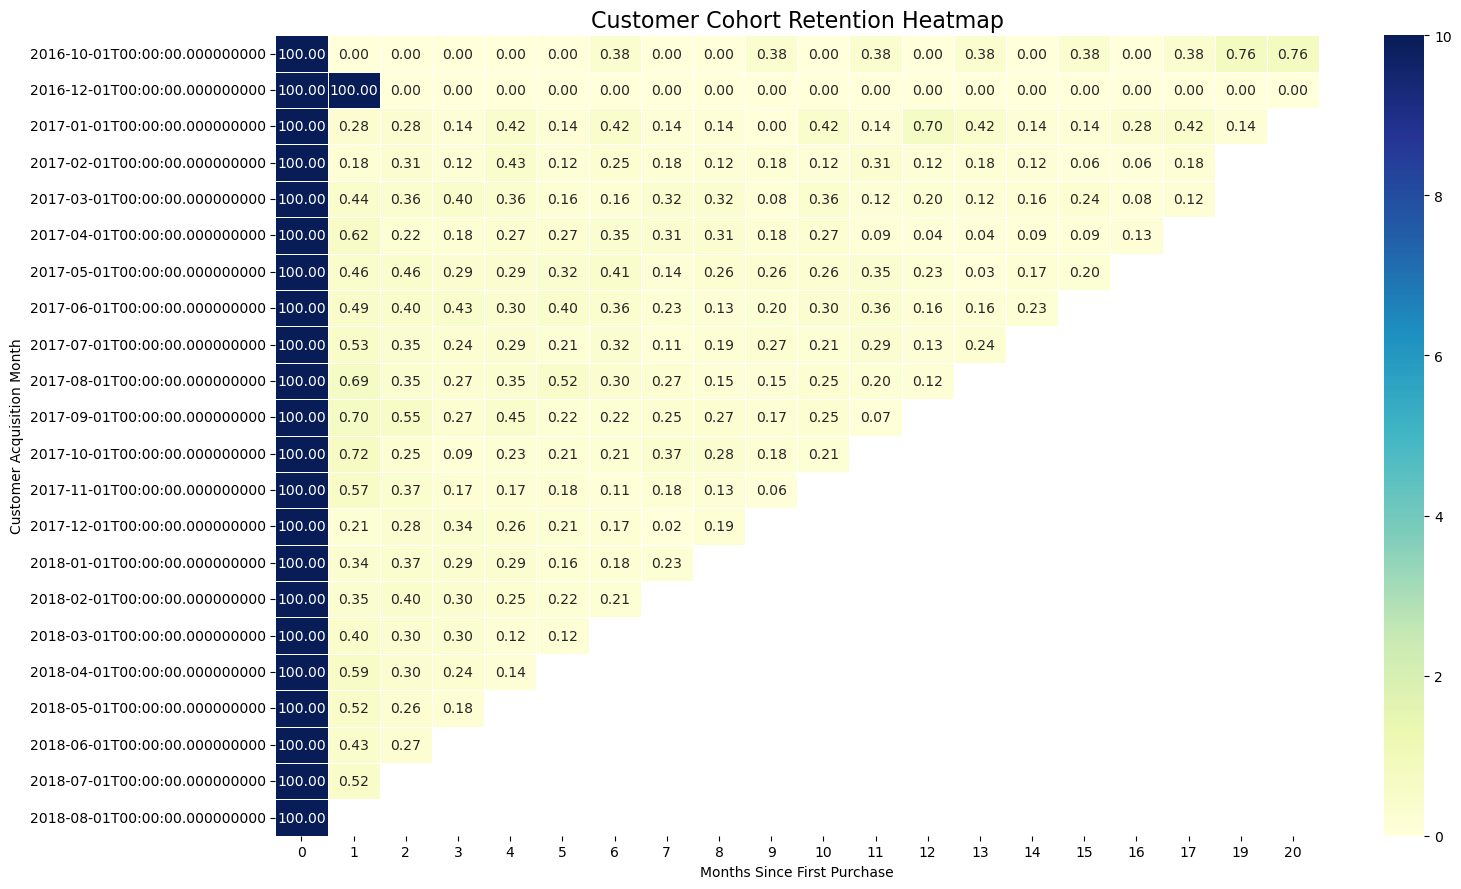

In [20]:
plt.figure(figsize=(16, 9))

sns.heatmap(
    retention_percentage,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=10
)

plt.title("Customer Cohort Retention Heatmap", fontsize=16)
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Acquisition Month")

plt.tight_layout()

# Product Performance Analysis

In [21]:
products = dataframes["product_performance"].copy()

print("Shape:", products.shape)
print("\nColumns:")
print(products.columns.tolist())

display(products.head())

Shape: (32216, 5)

Columns:
['product_id', 'total_orders', 'units_sold', 'total_revenue', 'avg_selling_price']


,product_id,total_orders,units_sold,total_revenue,avg_selling_price
0,00066f42aeeb9f3007548bb9d3f33c38,1,1.0,101.65,101.65
1,00088930e925c41fd95ebfe695fd2655,1,1.0,129.90,129.90
2,0009406fd7479715e4bef61dd91f2462,1,1.0,229.00,229.00
3,000b8f95fcb9e0096488278317764d19,2,2.0,117.80,58.90
4,000d9be29b5207b54e86aa1b1ac54872,1,1.0,199.00,199.00


# Identify the top 10 products by revenue

In [22]:
top_products = products.nlargest(10, "total_revenue")

display(
    top_products[
        [
            "product_id",
            "total_orders",
            "units_sold",
            "total_revenue",
            "avg_selling_price"
        ]
    ]
)

,product_id,total_orders,units_sold,total_revenue,avg_selling_price
23546,bb50f2e236e5eea0100680137654686c,186,194.0,63560.00,327.63
13749,6cdd53843498f92890544667809f1595,148,153.0,53652.30,350.67
26997,d6160fb7873f184099d9bc95e30376af,33,33.0,45949.35,1392.40
26436,d1c427060a0f73f6b889a5c7c61f2ac4,313,332.0,45620.56,137.41
19290,99a4788cb24856965c36a24e339b6058,456,477.0,42049.66,88.15
7881,3dd2a17168ec895c781a9191c1e95ad7,253,272.0,40782.80,149.94
4892,25c38557cf793876c5abdd5931f922db,38,38.0,38907.32,1023.88
12074,5f504b3a1c75b73d6151be81eb05bdc9,63,63.0,37733.90,598.95
10616,53b36df67ebb7c41585e8d54d6772e08,304,321.0,37454.63,116.68
21617,aca2eb7d00ea1a7b8ebd4e68314663af,425,520.0,37104.30,71.35


# Visualize the top 10 products by revenue

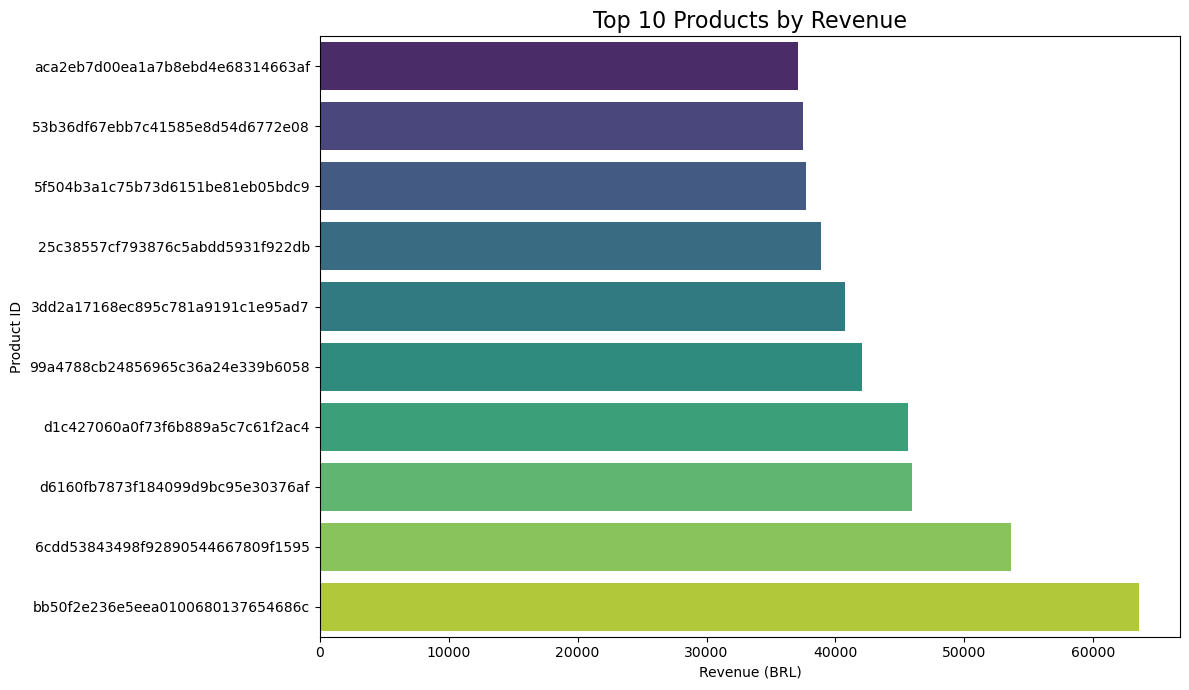

In [23]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products.sort_values("total_revenue", ascending=True),
    x="total_revenue",
    y="product_id",
    hue="product_id",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Products by Revenue", fontsize=16)
plt.xlabel("Revenue (BRL)")
plt.ylabel("Product ID")
plt.tight_layout()

# Top 10 products by units sold

In [24]:
top_products_by_units = products.nlargest(10, "units_sold")

display(
    top_products_by_units[
        [
            "product_id",
            "total_orders",
            "units_sold",
            "total_revenue",
            "avg_selling_price"
        ]
    ]
)

,product_id,total_orders,units_sold,total_revenue,avg_selling_price
21617,aca2eb7d00ea1a7b8ebd4e68314663af,425,520.0,37104.30,71.35
8429,422879e10f46682990de24d770e7f83d,352,484.0,26577.22,54.91
19290,99a4788cb24856965c36a24e339b6058,456,477.0,42049.66,88.15
7206,389d119b48cf3043d311335e499d9c6b,309,390.0,21336.79,54.71
6926,368c6c730842d78016ad823897a372db,291,388.0,21056.80,54.27
10589,53759a2ecddad2bb87a079a1f1519f73,287,373.0,20387.20,54.66
26436,d1c427060a0f73f6b889a5c7c61f2ac4,313,332.0,45620.56,137.41
10616,53b36df67ebb7c41585e8d54d6772e08,304,321.0,37454.63,116.68
2734,154e7e31ebfa092203795c972e5804a6,262,274.0,6173.26,22.53
7881,3dd2a17168ec895c781a9191c1e95ad7,253,272.0,40782.80,149.94


# Visualize top 10 products by units sold

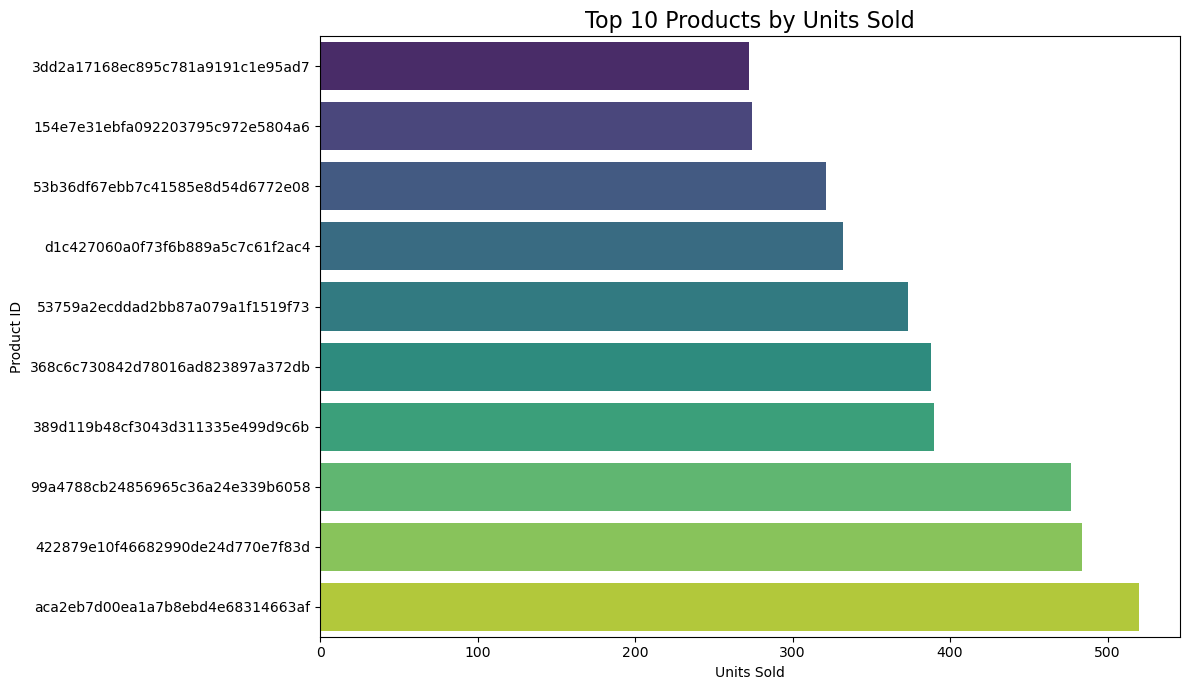

In [25]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products_by_units.sort_values("units_sold", ascending=True),
    x="units_sold",
    y="product_id",
    hue="product_id",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Products by Units Sold", fontsize=16)
plt.xlabel("Units Sold")
plt.ylabel("Product ID")
plt.tight_layout()

# Category Performance Analysis.

In [26]:
categories = dataframes["category_performance"].copy()

print("Shape:", categories.shape)
print("\nColumns:")
print(categories.columns.tolist())

display(categories.head())

Shape: (74, 5)

Columns:
['category_name', 'total_orders', 'units_sold', 'total_revenue', 'avg_selling_price']


,category_name,total_orders,units_sold,total_revenue,avg_selling_price
0,health_beauty,8647,9465,1233131.72,130.28
1,watches_gifts,5495,5859,1166176.98,199.04
2,bed_bath_table,9272,10953,1023434.76,93.44
3,sports_leisure,7530,8431,954852.55,113.25
4,computers_accessories,6530,7644,888724.61,116.26


# Top 10 categories by revenue

In [27]:
top_categories = categories.nlargest(10, "total_revenue")

display(
    top_categories[
        [
            "category_name",
            "total_orders",
            "units_sold",
            "total_revenue",
            "avg_selling_price"
        ]
    ]
)

,category_name,total_orders,units_sold,total_revenue,avg_selling_price
0,health_beauty,8647,9465,1233131.72,130.28
1,watches_gifts,5495,5859,1166176.98,199.04
2,bed_bath_table,9272,10953,1023434.76,93.44
3,sports_leisure,7530,8431,954852.55,113.25
4,computers_accessories,6530,7644,888724.61,116.26
5,furniture_decor,6307,8160,711927.69,87.25
6,housewares,5743,6795,615628.69,90.60
7,cool_stuff,3559,3718,610204.10,164.12
8,auto,3810,4140,578966.65,139.85
9,toys,3804,4030,471286.48,116.94


# Visualize top 10 categories by revenue

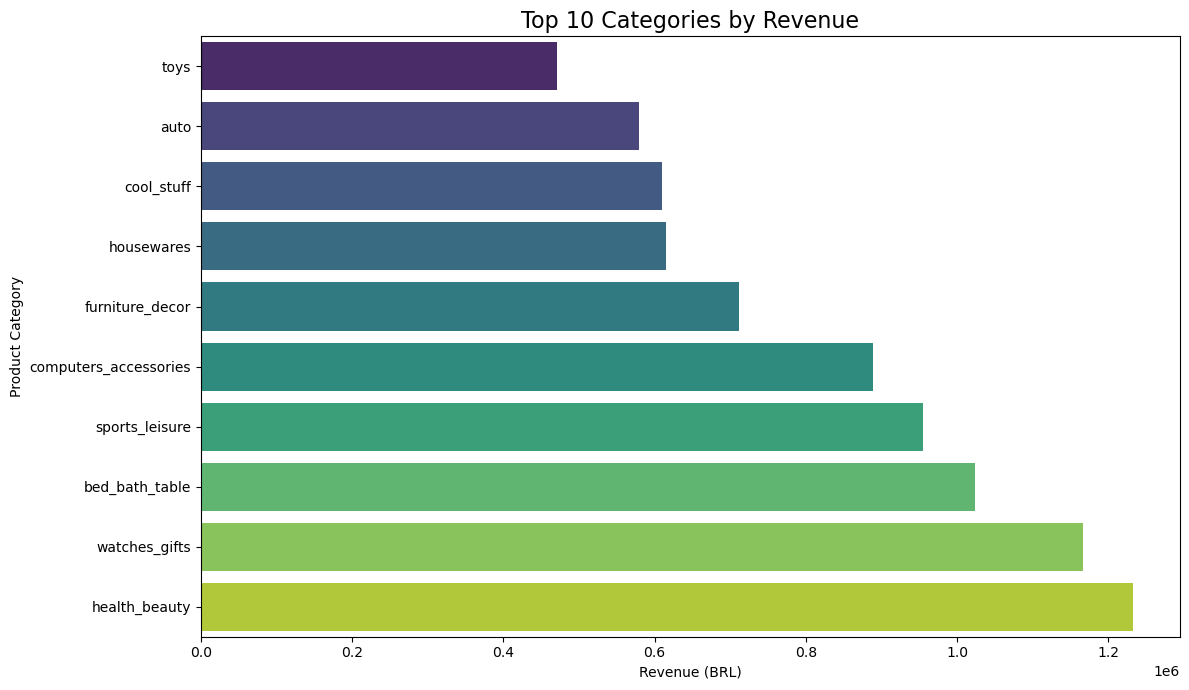

In [28]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_categories.sort_values("total_revenue", ascending=True),
    x="total_revenue",
    y="category_name",
    hue="category_name",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Categories by Revenue", fontsize=16)
plt.xlabel("Revenue (BRL)")
plt.ylabel("Product Category")
plt.tight_layout()

# Category sales volume

In [29]:
top_categories_by_units = categories.nlargest(10, "units_sold")

display(
    top_categories_by_units[
        [
            "category_name",
            "total_orders",
            "units_sold",
            "total_revenue",
            "avg_selling_price"
        ]
    ]
)

,category_name,total_orders,units_sold,total_revenue,avg_selling_price
2,bed_bath_table,9272,10953,1023434.76,93.44
0,health_beauty,8647,9465,1233131.72,130.28
3,sports_leisure,7530,8431,954852.55,113.25
5,furniture_decor,6307,8160,711927.69,87.25
4,computers_accessories,6530,7644,888724.61,116.26
6,housewares,5743,6795,615628.69,90.60
1,watches_gifts,5495,5859,1166176.98,199.04
13,telephony,4093,4430,309860.23,69.95
10,garden_tools,3448,4268,470495.28,110.24
8,auto,3810,4140,578966.65,139.85


# Visualize category sales volume

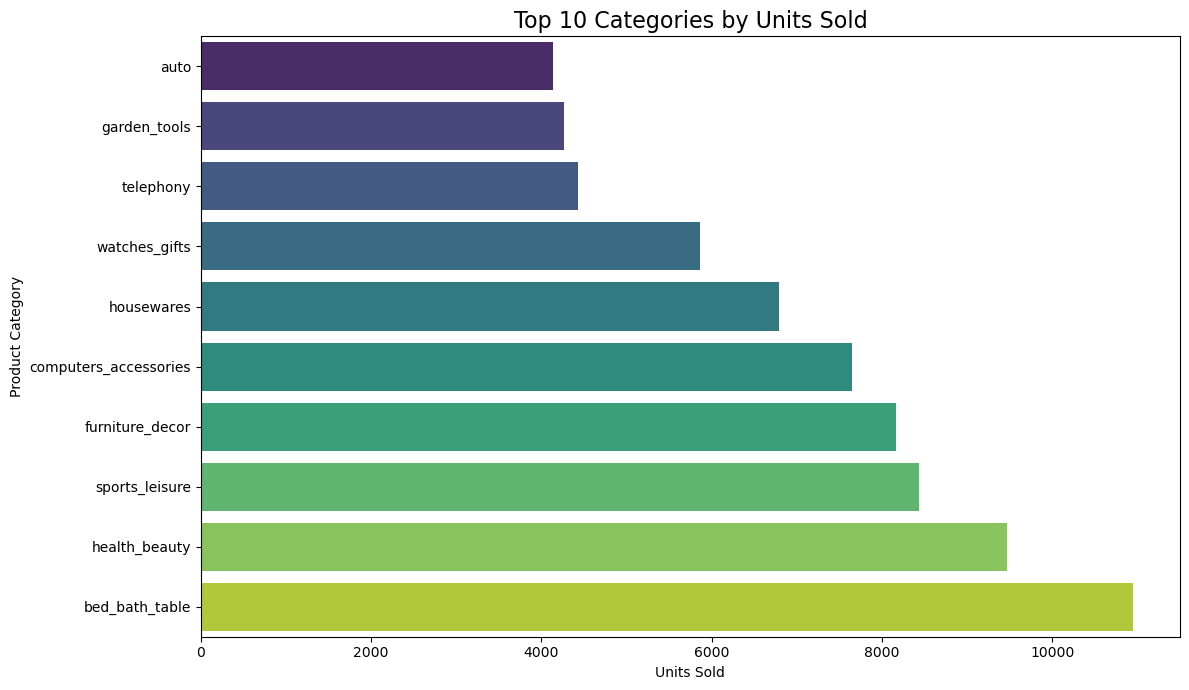

In [30]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_categories_by_units.sort_values("units_sold", ascending=True),
    x="units_sold",
    y="category_name",
    hue="category_name",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Categories by Units Sold", fontsize=16)
plt.xlabel("Units Sold")
plt.ylabel("Product Category")
plt.tight_layout()

# Category revenue contribution

In [31]:
categories["revenue_contribution_pct"] = (
    categories["total_revenue"] /
    categories["total_revenue"].sum()
) * 100

top_categories_contribution = categories.nlargest(
    10, "revenue_contribution_pct"
)

display(
    top_categories_contribution[
        [
            "category_name",
            "total_revenue",
            "revenue_contribution_pct"
        ]
    ].round(2)
)

,category_name,total_revenue,revenue_contribution_pct
0,health_beauty,1233131.72,9.33
1,watches_gifts,1166176.98,8.82
2,bed_bath_table,1023434.76,7.74
3,sports_leisure,954852.55,7.22
4,computers_accessories,888724.61,6.72
5,furniture_decor,711927.69,5.38
6,housewares,615628.69,4.66
7,cool_stuff,610204.10,4.62
8,auto,578966.65,4.38
9,toys,471286.48,3.56


# Visualize revenue contribution

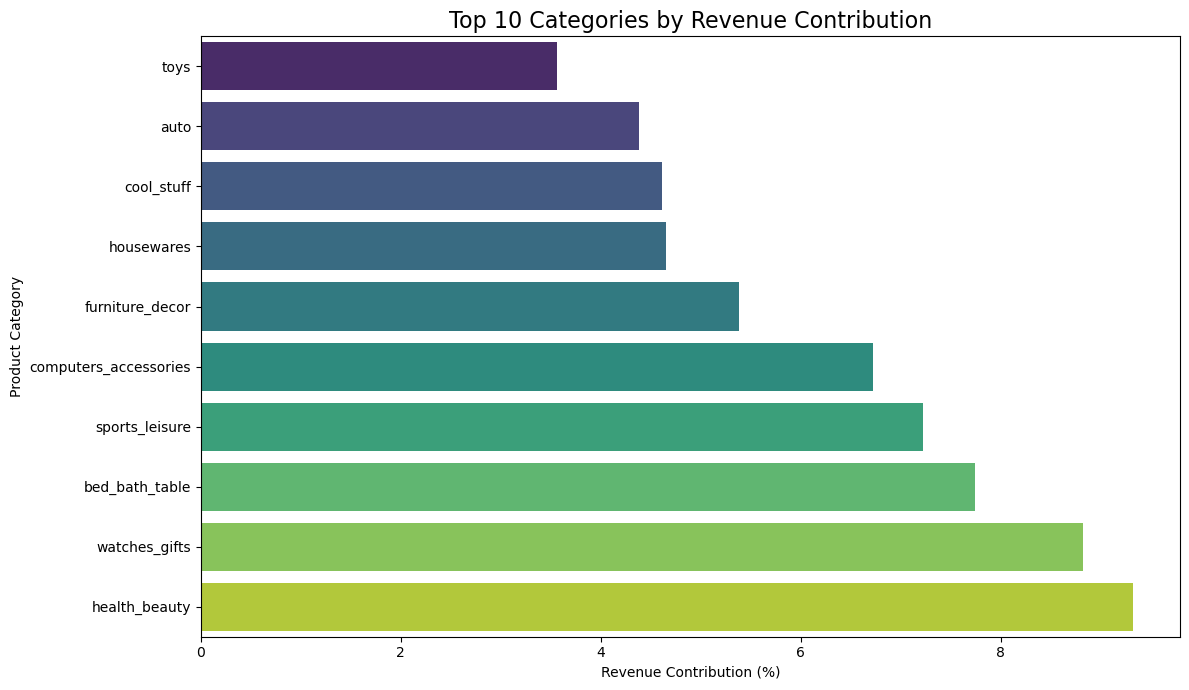

In [32]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_categories_contribution.sort_values(
        "revenue_contribution_pct",
        ascending=True
    ),
    x="revenue_contribution_pct",
    y="category_name",
    hue="category_name",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Categories by Revenue Contribution", fontsize=16)
plt.xlabel("Revenue Contribution (%)")
plt.ylabel("Product Category")
plt.tight_layout()

# Identify top 10 sellers by revenue

In [33]:
sellers = dataframes["seller_performance"].copy()

print("Seller Dataset Shape:", sellers.shape)
display(sellers.head())
print("\nColumns:")
print(sellers.columns.tolist())

Seller Dataset Shape: (2970, 5)


,seller_id,total_orders,units_sold,total_revenue,avg_selling_price
0,4869f7a5dfa277a7dca6462dcf3b52b2,1124,1148,226987.93,197.72
1,53243585a1d6dc2643021fd1853d8905,348,400,217940.44,544.85
2,4a3ca9315b744ce9f8e9374361493884,1772,1949,196882.12,101.02
3,fa1c13f2614d7b5c4749cbc52fecda94,578,579,190917.14,329.74
4,7c67e1448b00f6e969d365cea6b010ab,973,1355,186570.05,137.69



Columns:
['seller_id', 'total_orders', 'units_sold', 'total_revenue', 'avg_selling_price']


# Top 10 sellers by revenue

In [34]:
top_sellers = sellers.nlargest(10, "total_revenue")

display(
    top_sellers[
        [
            "seller_id",
            "total_orders",
            "units_sold",
            "total_revenue",
            "avg_selling_price"
        ]
    ]
)

,seller_id,total_orders,units_sold,total_revenue,avg_selling_price
0,4869f7a5dfa277a7dca6462dcf3b52b2,1124,1148,226987.93,197.72
1,53243585a1d6dc2643021fd1853d8905,348,400,217940.44,544.85
2,4a3ca9315b744ce9f8e9374361493884,1772,1949,196882.12,101.02
3,fa1c13f2614d7b5c4749cbc52fecda94,578,579,190917.14,329.74
4,7c67e1448b00f6e969d365cea6b010ab,973,1355,186570.05,137.69
5,7e93a43ef30c4f03f38b393420bc753a,319,322,165981.49,515.47
6,da8622b14eb17ae2831f4ac5b9dab84a,1311,1548,159816.87,103.24
7,7a67c85e85bb2ce8582c35f2203ad736,1145,1155,139658.69,120.92
8,1025f0e2d44d7041d6cf58b6550e0bfa,910,1420,138208.56,97.33
9,955fee9216a65b617aa5c0531780ce60,1261,1472,131836.71,89.56


# Visualize top 10 sellers by revenue

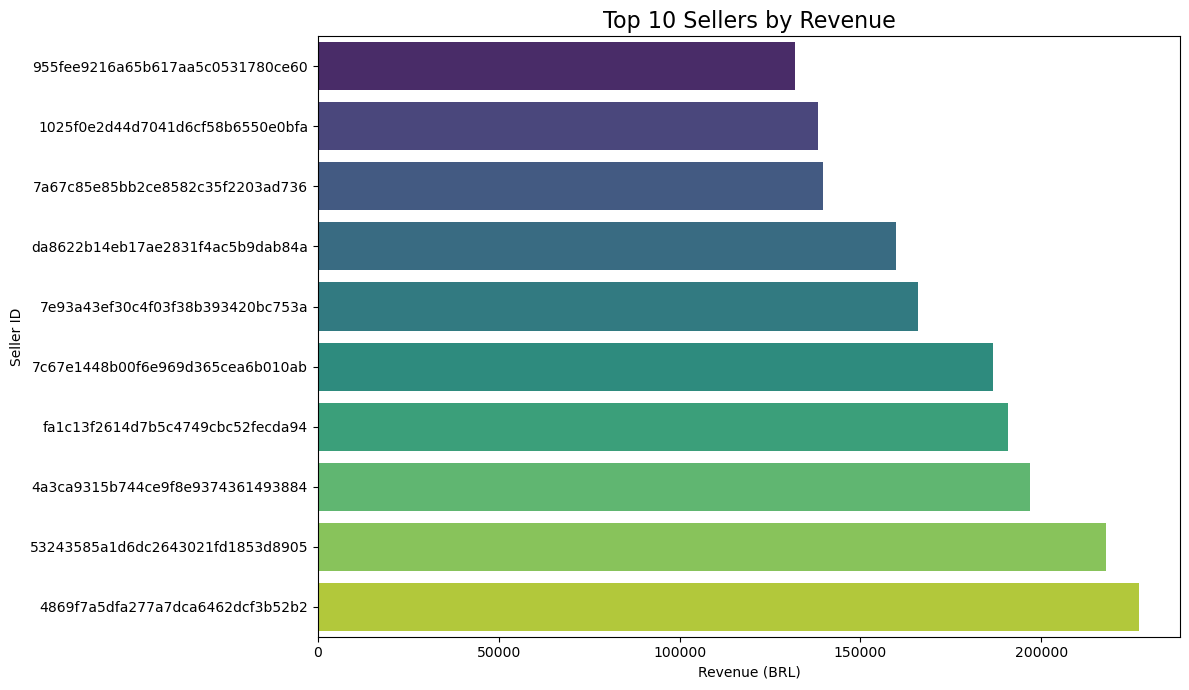

In [35]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_sellers.sort_values("total_revenue", ascending=True),
    x="total_revenue",
    y="seller_id",
    hue="seller_id",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Sellers by Revenue", fontsize=16)
plt.xlabel("Revenue (BRL)")
plt.ylabel("Seller ID")
plt.tight_layout()

# Top 10 sellers by order volume

In [36]:
top_sellers_by_orders = sellers.nlargest(10, "total_orders")

display(
    top_sellers_by_orders[
        [
            "seller_id",
            "total_orders",
            "units_sold",
            "total_revenue",
            "avg_selling_price"
        ]
    ]
)

,seller_id,total_orders,units_sold,total_revenue,avg_selling_price
11,6560211a19b47992c3666cc44a7e94c0,1819,1996,120702.83,60.47
2,4a3ca9315b744ce9f8e9374361493884,1772,1949,196882.12,101.02
16,cc419e0650a3c5ba77189a1882b7556a,1651,1719,101090.96,58.81
15,1f50f920176fa81dab994f9023523100,1399,1926,106655.71,55.38
6,da8622b14eb17ae2831f4ac5b9dab84a,1311,1548,159816.87,103.24
9,955fee9216a65b617aa5c0531780ce60,1261,1472,131836.71,89.56
7,7a67c85e85bb2ce8582c35f2203ad736,1145,1155,139658.69,120.92
62,ea8482cd71df3c1969d7b9473ff13abc,1132,1188,36696.76,30.89
0,4869f7a5dfa277a7dca6462dcf3b52b2,1124,1148,226987.93,197.72
18,3d871de0142ce09b7081e2b9d1733cb1,1064,1131,93407.40,82.59


# Visualize top 10 sellers by orders

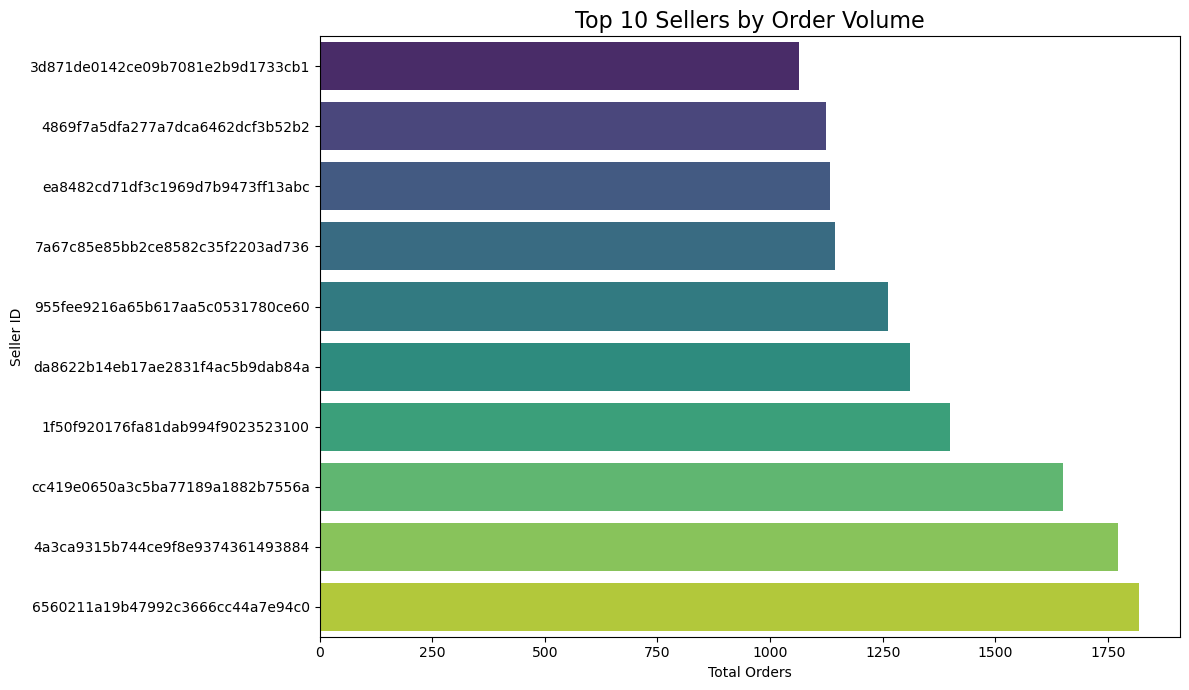

In [37]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_sellers_by_orders.sort_values(
        "total_orders",
        ascending=True
    ),
    x="total_orders",
    y="seller_id",
    hue="seller_id",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Sellers by Order Volume", fontsize=16)
plt.xlabel("Total Orders")
plt.ylabel("Seller ID")
plt.tight_layout()

# Understand payment data

In [38]:
payments = dataframes["payment_analytics"].copy()

print("Payment Dataset Shape:", payments.shape)

display(payments)

print("\nColumn Names:")
print(payments.columns.tolist())

Payment Dataset Shape: (4, 7)


,payment_type,payment_records,total_orders,total_payment_value,avg_payment_value,avg_installments,revenue_percentage
0,credit_card,74586,74304,12101094.88,162.24,3.5,78.46
1,boleto,19191,19191,2769932.58,144.33,1.0,17.96
2,voucher,5493,3679,343013.19,62.45,1.0,2.22
3,debit_card,1486,1485,208421.12,140.26,1.0,1.35



Column Names:
['payment_type', 'payment_records', 'total_orders', 'total_payment_value', 'avg_payment_value', 'avg_installments', 'revenue_percentage']


# Visualize payment method revenue

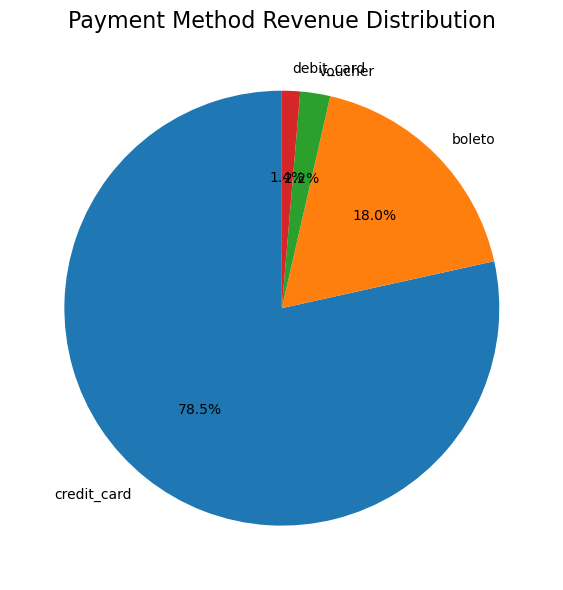

In [39]:
plt.figure(figsize=(9, 6))

plt.pie(
    payments["total_payment_value"],
    labels=payments["payment_type"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Payment Method Revenue Distribution", fontsize=16)
plt.tight_layout()

# Compare average payment values

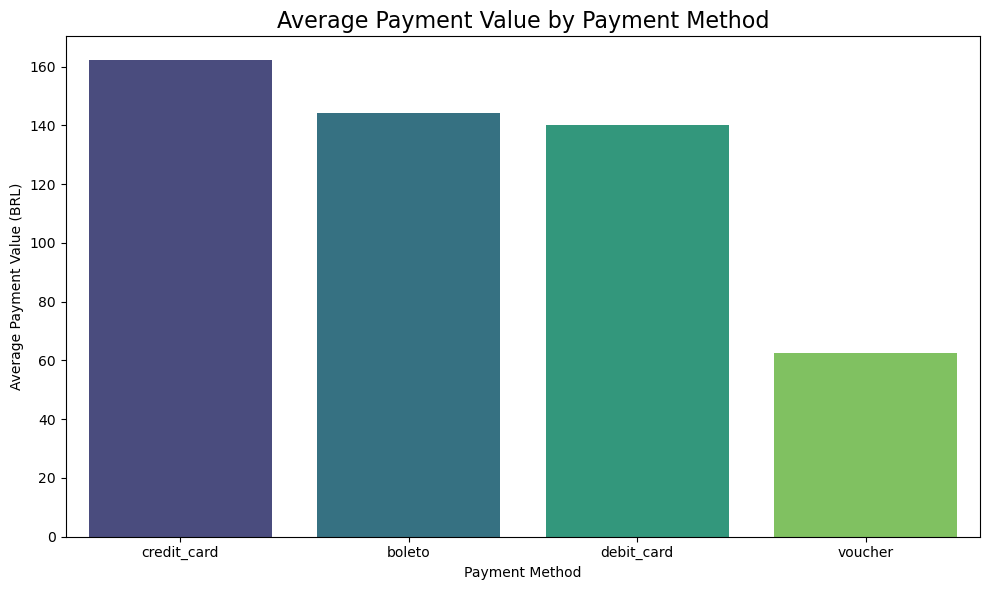

In [40]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=payments.sort_values(
        "avg_payment_value",
        ascending=False
    ),
    x="payment_type",
    y="avg_payment_value",
    hue="payment_type",
    palette="viridis",
    legend=False
)

plt.title("Average Payment Value by Payment Method", fontsize=16)
plt.xlabel("Payment Method")
plt.ylabel("Average Payment Value (BRL)")
plt.tight_layout()

# Delivery Performance and Customer Reviews

In [41]:
delivery = dataframes["delivery_review_analytics"].copy()

print("Dataset Shape:", delivery.shape)
print("\nColumn Names:")
print(delivery.columns.tolist())

print("\nSample Records:")
display(delivery.head())

Dataset Shape: (23, 7)

Column Names:
['sales_month', 'delivered_orders', 'avg_delivery_days', 'late_deliveries', 'reviewed_orders', 'avg_review_score', 'negative_review_orders']

Sample Records:


,sales_month,delivered_orders,avg_delivery_days,late_deliveries,reviewed_orders,avg_review_score,negative_review_orders
0,2016-09-01,1,54.81,1,1,1.00,1
1,2016-10-01,265,19.60,3,262,4.01,43
2,2016-12-01,1,4.69,0,1,5.00,0
3,2017-01-01,750,12.65,23,741,4.20,89
4,2017-02-01,1653,13.17,53,1643,4.20,182


# Calculate delivery and review KPIs

In [42]:
total_delivered = delivery["delivered_orders"].sum()

total_late = delivery["late_deliveries"].sum()

total_reviewed = delivery["reviewed_orders"].sum()

total_negative_reviews = delivery["negative_review_orders"].sum()

late_delivery_rate = (total_late / total_delivered) * 100

negative_review_rate = (
    total_negative_reviews / total_reviewed
) * 100

weighted_avg_delivery_days = (
    (delivery["avg_delivery_days"] * delivery["delivered_orders"]).sum()
    / total_delivered
)

weighted_avg_review_score = (
    (delivery["avg_review_score"] * delivery["reviewed_orders"]).sum()
    / total_reviewed
)

print(f"Total Delivered Orders: {total_delivered:,}")
print(f"Total Late Deliveries: {total_late:,}")
print(f"Late Delivery Rate: {late_delivery_rate:.2f}%")
print(f"Weighted Average Delivery Days: {weighted_avg_delivery_days:.2f}")
print(f"Total Reviewed Orders: {total_reviewed:,}")
print(f"Negative Review Rate: {negative_review_rate:.2f}%")
print(f"Weighted Average Review Score: {weighted_avg_review_score:.2f}/5")

Total Delivered Orders: 96,470
Total Late Deliveries: 7,826
Late Delivery Rate: 8.11%
Weighted Average Delivery Days: 12.56
Total Reviewed Orders: 95,832
Negative Review Rate: 12.77%
Weighted Average Review Score: 4.16/5


# Monthly Delivery Time Trend

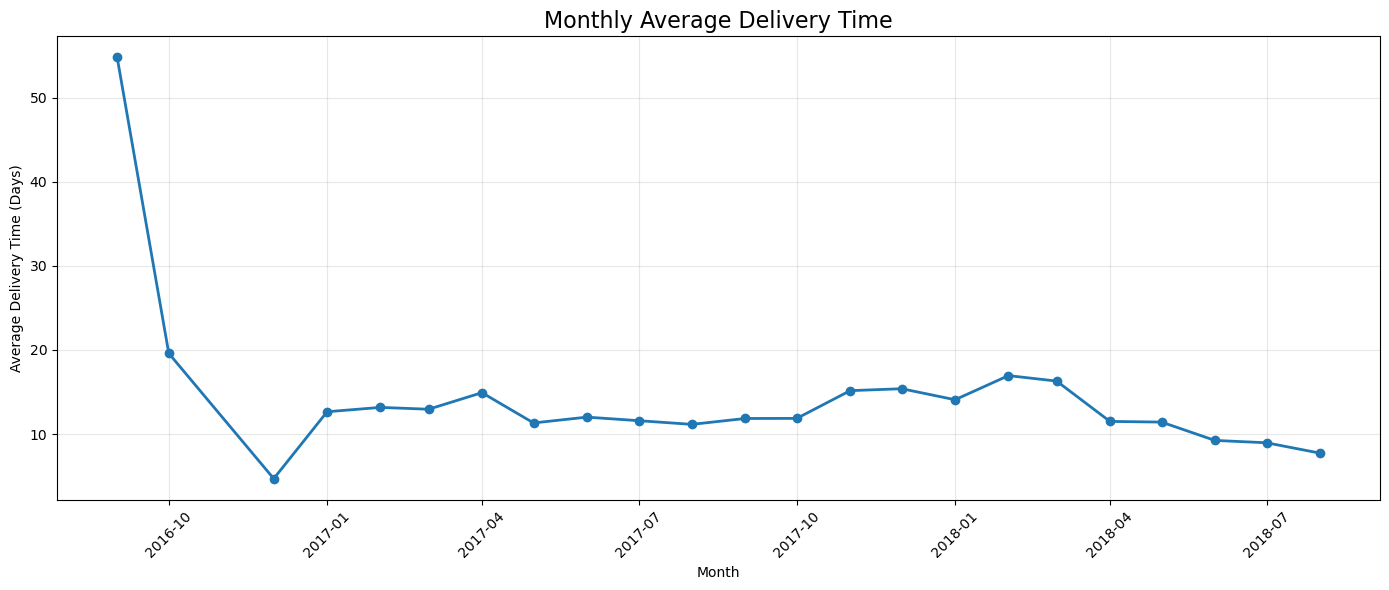

In [43]:
delivery["sales_month"] = pd.to_datetime(delivery["sales_month"])
delivery = delivery.sort_values("sales_month")

plt.figure(figsize=(14, 6))

plt.plot(
    delivery["sales_month"],
    delivery["avg_delivery_days"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Delivery Time", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Average Delivery Time (Days)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Monthly Late Delivery Trend

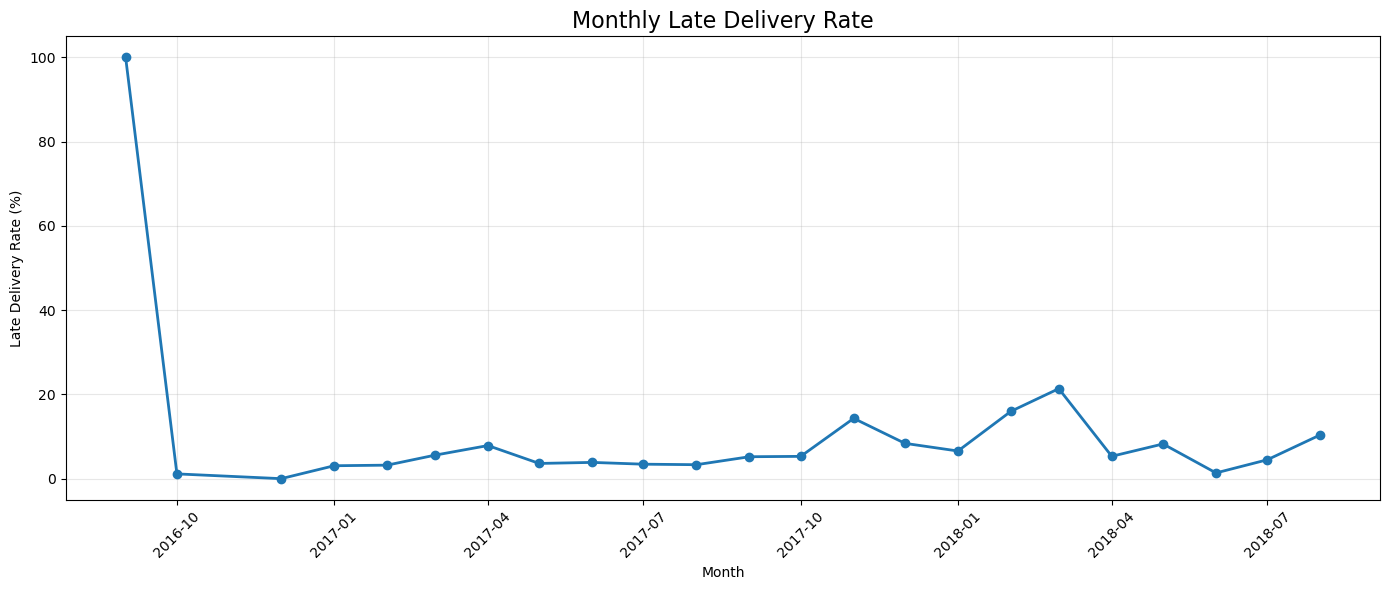

In [44]:
delivery["sales_month"] = pd.to_datetime(delivery["sales_month"])

delivery["late_delivery_rate"] = (
    delivery["late_deliveries"]
    / delivery["delivered_orders"]
) * 100

delivery = delivery.sort_values("sales_month")

plt.figure(figsize=(14, 6))

plt.plot(
    delivery["sales_month"],
    delivery["late_delivery_rate"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Late Delivery Rate", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Late Delivery Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Monthly Customer Review Score Trend

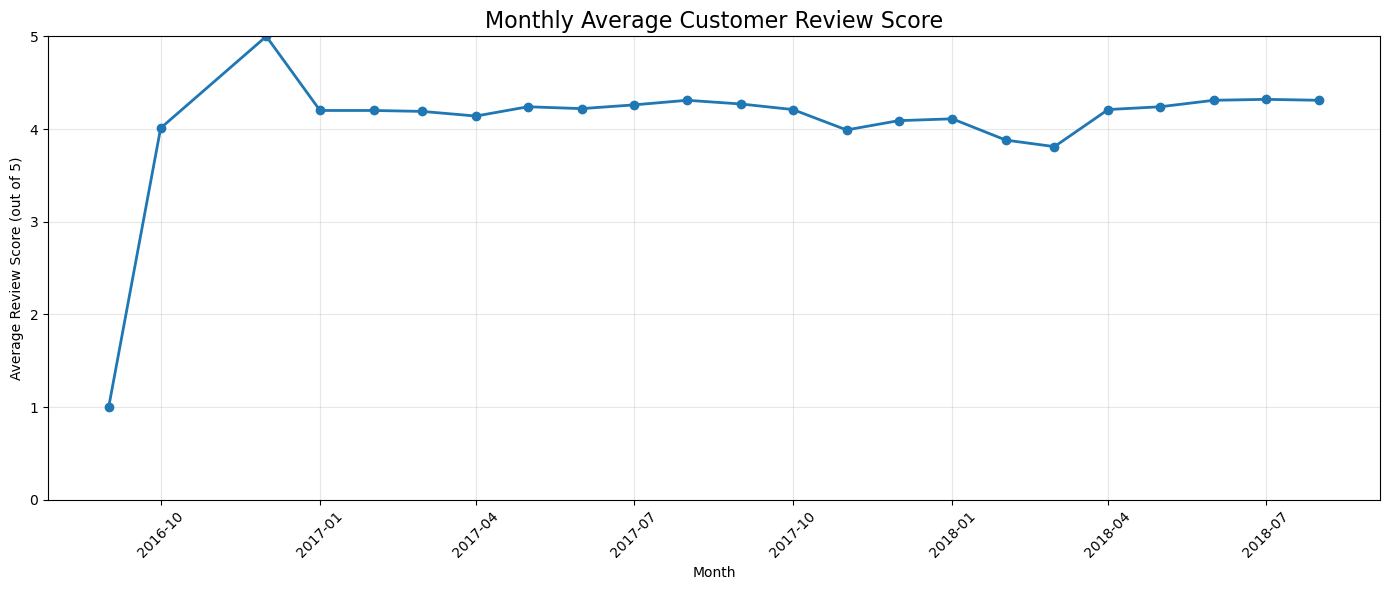

In [45]:
plt.figure(figsize=(14, 6))

plt.plot(
    delivery["sales_month"],
    delivery["avg_review_score"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Customer Review Score", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Average Review Score (out of 5)")
plt.ylim(0, 5)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Monthly Negative Review Trend

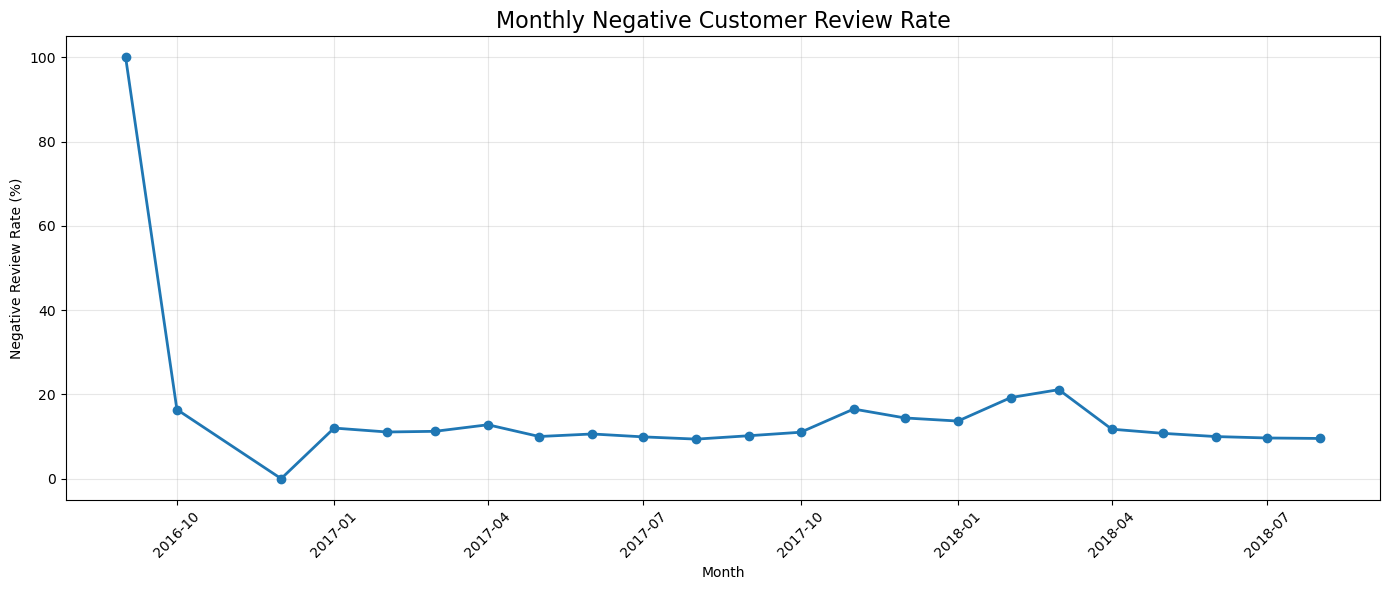

In [46]:
delivery["negative_review_rate"] = (
    delivery["negative_review_orders"]
    / delivery["reviewed_orders"]
) * 100

plt.figure(figsize=(14, 6))

plt.plot(
    delivery["sales_month"],
    delivery["negative_review_rate"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Negative Customer Review Rate", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Negative Review Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Consolidated Business Insights

In [47]:
# Best and worst months
worst_late_month = delivery.loc[
    delivery["late_delivery_rate"].idxmax()
]

best_late_month = delivery.loc[
    delivery["late_delivery_rate"].idxmin()
]

best_review_month = delivery.loc[
    delivery["avg_review_score"].idxmax()
]

worst_review_month = delivery.loc[
    delivery["avg_review_score"].idxmin()
]

print("========== DELIVERY INSIGHTS ==========")

print(
    f"Highest Late Delivery Rate: "
    f"{worst_late_month['late_delivery_rate']:.2f}% "
    f"({worst_late_month['sales_month'].strftime('%b %Y')})"
)

print(
    f"Lowest Late Delivery Rate: "
    f"{best_late_month['late_delivery_rate']:.2f}% "
    f"({best_late_month['sales_month'].strftime('%b %Y')})"
)

print("\n========== CUSTOMER SATISFACTION ==========")

print(
    f"Highest Average Review Score: "
    f"{best_review_month['avg_review_score']:.2f}/5 "
    f"({best_review_month['sales_month'].strftime('%b %Y')})"
)

print(
    f"Lowest Average Review Score: "
    f"{worst_review_month['avg_review_score']:.2f}/5 "
    f"({worst_review_month['sales_month'].strftime('%b %Y')})"
)

print("\n========== OVERALL KPIs ==========")

print(f"Late Delivery Rate: {late_delivery_rate:.2f}%")
print(f"Average Delivery Time: {weighted_avg_delivery_days:.2f} days")
print(f"Negative Review Rate: {negative_review_rate:.2f}%")
print(f"Average Review Score: {weighted_avg_review_score:.2f}/5")

========== DELIVERY INSIGHTS ==========
Highest Late Delivery Rate: 100.00% (Sep 2016)
Lowest Late Delivery Rate: 0.00% (Dec 2016)

========== CUSTOMER SATISFACTION ==========
Highest Average Review Score: 5.00/5 (Dec 2016)
Lowest Average Review Score: 1.00/5 (Sep 2016)

========== OVERALL KPIs ==========
Late Delivery Rate: 8.11%
Average Delivery Time: 12.56 days
Negative Review Rate: 12.77%
Average Review Score: 4.16/5


# Filter reliable monthly comparisons

In [48]:
reliable_delivery = delivery[
    delivery["delivered_orders"] >= 100
].copy()

print("Months included:", len(reliable_delivery))

print("\nHighest Late Delivery Rate:")
display(
    reliable_delivery.nlargest(
        1, "late_delivery_rate"
    )[["sales_month", "delivered_orders", "late_delivery_rate"]]
)

print("\nLowest Late Delivery Rate:")
display(
    reliable_delivery.nsmallest(
        1, "late_delivery_rate"
    )[["sales_month", "delivered_orders", "late_delivery_rate"]]
)

print("\nLowest Average Review Score:")
display(
    reliable_delivery.nsmallest(
        1, "avg_review_score"
    )[["sales_month", "reviewed_orders", "avg_review_score"]]
)

Months included: 21

Highest Late Delivery Rate:


,sales_month,delivered_orders,late_delivery_rate
17,2018-03-01,7003,21.362273



Lowest Late Delivery Rate:


,sales_month,delivered_orders,late_delivery_rate
1,2016-10-01,265,1.132075



Lowest Average Review Score:


,sales_month,reviewed_orders,avg_review_score
17,2018-03-01,6948,3.81


# Compare delivery delays and customer satisfaction

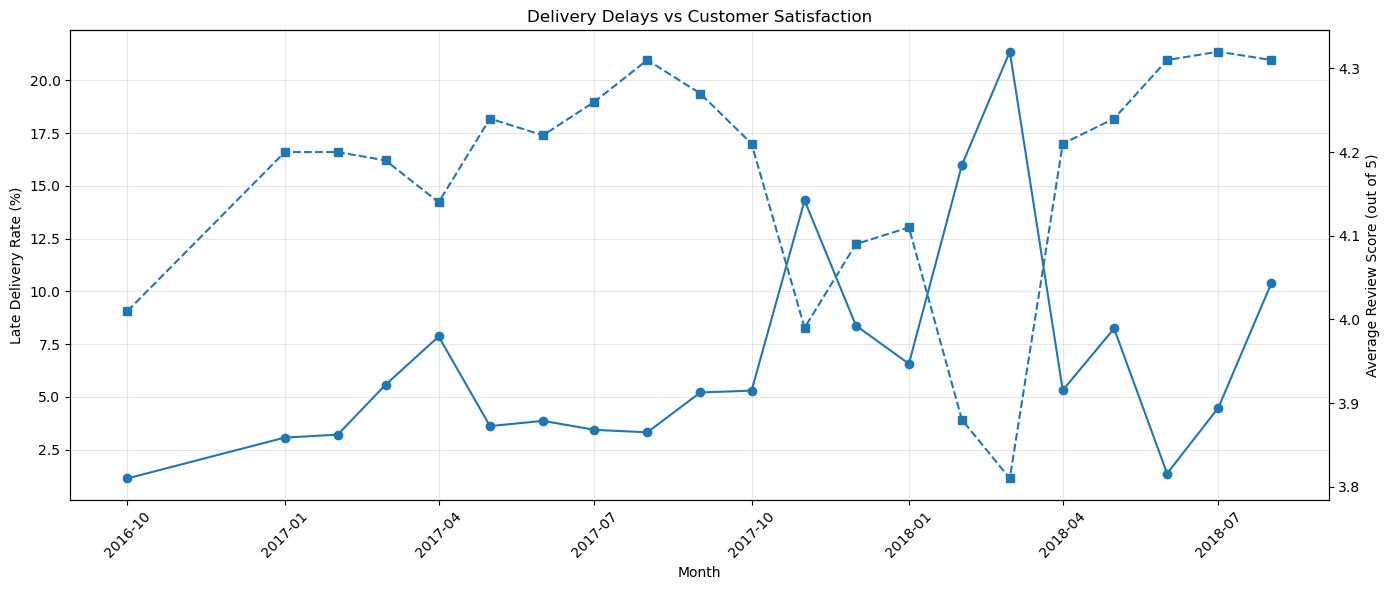

In [49]:
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(
    reliable_delivery["sales_month"],
    reliable_delivery["late_delivery_rate"],
    marker="o",
    label="Late Delivery Rate (%)"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Late Delivery Rate (%)")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()

ax2.plot(
    reliable_delivery["sales_month"],
    reliable_delivery["avg_review_score"],
    marker="s",
    linestyle="--",
    label="Average Review Score"
)

ax2.set_ylabel("Average Review Score (out of 5)")

plt.title("Delivery Delays vs Customer Satisfaction")
fig.tight_layout()

# Calculate the correlation

In [50]:
correlation = reliable_delivery[
    ["late_delivery_rate", "avg_review_score"]
].corr().iloc[0, 1]

print(f"Correlation: {correlation:.3f}")

Correlation: -0.744
